# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [6]:
ROLL_NO = 1024170214       # <-- your full roll number
NAME = "Siya Garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [7]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [8]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [9]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170214   Name: Siya Garg   Fingerprint: ED044AE6   Tickets: 16

Ticket_ID                                                                               Ticket_Text
      T01    MATLAB was working yesterday when I use mobile hotspot. The same problem occurs again.
      T02                I cannot access the printer while uploading the file. It worked yesterday.
      T03                                             The server failed to open. Please resolve it.
      T04                                Python stopped responding since yesterday. This is urgent.
      T05                                             The wifi is not working. It worked yesterday.
      T06                                                     Nothing works and nobody has replied.
      T07                                              The password failed to open. This is urgent.
      T08                                                               The file is 95.5% uploaded.
      T09          

In [10]:
import nltk
import pandas as pd
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

results = []

for _, row in df.iterrows():
    ticket = row['Ticket_Text']
    processed = process_ticket(ticket)
    print(processed)
    break

{'sentences': ['MATLAB was working yesterday when I use mobile hotspot.', 'The same problem occurs again.'], 'tokens': ['matlab', 'was', 'working', 'yesterday', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'the', 'same', 'problem', 'occurs', 'again', '.'], 'punct': ['.', '.'], 'stops': ['was', 'when', 'i', 'the', 'same', 'again'], 'final': ['matlab', 'working', 'yesterday', 'use', 'mobile', 'hotspot', 'problem', 'occurs']}


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
results = []

for _, row in df.iterrows():
    ticket = row['Ticket_Text']
    p = process_ticket(ticket)

    results.append({
        'Ticket': row['Ticket_ID'],
        'Sentences': len(p['sentences']),
        'Tokens': len(p['tokens']),
        'Punctuation Tokens': len(p['punct']),
        'Stopwords': len(p['stops']),
        'Unique Tokens': len(set(p['tokens'])),
        'Final Tokens': len(p['final'])
    })

result_df = pd.DataFrame(results)

total = {'Ticket': 'TOTAL'}
for col in result_df.columns[1:]:
    total[col] = result_df[col].sum()

result_df = pd.concat(
    [result_df, pd.DataFrame([total])],
    ignore_index=True
)

display(result_df)

,Ticket,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,6,15,8
1,T02,2,15,2,7,13,6
2,T03,2,10,2,3,9,5
3,T04,2,10,2,2,9,6
4,T05,2,10,2,4,9,4
5,T06,1,7,1,2,7,4
6,T07,2,10,2,4,9,4
7,T08,1,7,2,2,7,3
8,T09,1,9,1,3,9,5
9,T10,1,7,2,1,7,4


In [12]:
p = process_ticket(df.iloc[0]['Ticket_Text'])

print("Actual tokens:", p['tokens'])
print("Punctuation tokens:", p['punct'])
print("Stopwords:", p['stops'])
print("Final tokens:", p['final'])

Actual tokens: ['matlab', 'was', 'working', 'yesterday', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['was', 'when', 'i', 'the', 'same', 'again']
Final tokens: ['matlab', 'working', 'yesterday', 'use', 'mobile', 'hotspot', 'problem', 'occurs']


---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [14]:
import re

for _, row in df.iterrows():
    ticket = row['Ticket_Text']

    print("\nTicket:", row['Ticket_ID'])
    print("Words longer than 5 letters:", re.findall(r'\b[A-Za-z]{6,}\b', ticket))
    print("Numbers, decimals and versions:", re.findall(r'\b\d+(?:\.\d+)+\b|\b\d+\b', ticket))
    print("Capitalized words:", re.findall(r'\b[A-Z][a-zA-Z]*\b', ticket))
    print("Words beginning with a vowel:", re.findall(r'\b[AEIOUaeiou][A-Za-z]*\b', ticket))


Ticket: T01
Words longer than 5 letters: ['MATLAB', 'working', 'yesterday', 'mobile', 'hotspot', 'problem', 'occurs']
Numbers, decimals and versions: []
Capitalized words: ['MATLAB', 'I', 'The']
Words beginning with a vowel: ['I', 'use', 'occurs', 'again']

Ticket: T02
Words longer than 5 letters: ['cannot', 'access', 'printer', 'uploading', 'worked', 'yesterday']
Numbers, decimals and versions: []
Capitalized words: ['I', 'It']
Words beginning with a vowel: ['I', 'access', 'uploading', 'It']

Ticket: T03
Words longer than 5 letters: ['server', 'failed', 'Please', 'resolve']
Numbers, decimals and versions: []
Capitalized words: ['The', 'Please']
Words beginning with a vowel: ['open', 'it']

Ticket: T04
Words longer than 5 letters: ['Python', 'stopped', 'responding', 'yesterday', 'urgent']
Numbers, decimals and versions: []
Capitalized words: ['Python', 'This']
Words beginning with a vowel: ['is', 'urgent']

Ticket: T05
Words longer than 5 letters: ['working', 'worked', 'yesterday']
Nu

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Words longer than 5 letters:", re.findall(r'\b[A-Za-z]{6,}\b', line))
    print("Numbers:", re.findall(r'\b\d+(?:\.\d+)+\b|\b\d+\b', line))
    print("Capitalized words:", re.findall(r'\b[A-Z][a-zA-Z]*\b', line))
    print("Words beginning with a vowel:", re.findall(r'\b[AEIOUaeiou][A-Za-z]*\b', line))

    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b', '<EMAIL>', line)
    text = re.sub(r'https?://[^\s<>"\']+|www\.[^\s<>"\']+', '<URL>', text)
    text = re.sub(r'(?<!\w)(?:\+?\d{1,3}[-.\s]?)?(?:\(?\d{3,5}\)?[-.\s]?)\d{3,4}[-.\s]?\d{3,4}(?!\w)', '<PHONE>', text)

    print("After replacement:", text)


Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words beginning with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
After replacement: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words longer than 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Words beginning with a vowel: ['or', 'is']
After replacement: Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words longer than 5 letters: []
Numbers: ['5.30']
Capitaliz

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 5 words are capitalized only because they appear at the beginning of a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s<>"']+|www\.[^\s<>"']+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d{1,3}[-.\s]?(?:\(?\d{3,5}\)?[-.\s]?)\d{3,4}[-.\s]?\d{3,4}|\d+(?:\.\d+)+|\d+(?:,\d{3})*(?:\.\d+)?|[A-Za-z]+(?:[-'][A-Za-z]+)*|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

different_tickets = []

for _, row in df.iterrows():
    ticket = row['Ticket_Text']
    custom_tokens = my_tokenize(ticket)
    standard_tokens = word_tokenize(ticket)

    if custom_tokens != standard_tokens:
        different_tickets.append(row['Ticket_ID'])

    print("\nTicket:", row['Ticket_ID'])
    print("my_tokenize:", custom_tokens)
    print("word_tokenize:", standard_tokens)

print("\nNumber of tickets tokenized differently:", len(different_tickets))
print("Ticket IDs:", different_tickets)


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*4 tickets (T02, T09, T10, and T13) are tokenized differently by `my_tokenize()` and `word_tokenize()`.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [18]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer('ing$')
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    if tag.startswith('V'):
        return 'v'
    if tag.startswith('N'):
        return 'n'
    if tag.startswith('R'):
        return 'r'
    return 'n'

unique_tokens = sorted({
    token
    for _, row in df.iterrows()
    for token in process_ticket(row['Ticket_Text'])['final']
})

tagged_tokens = nltk.pos_tag(unique_tokens)
comparison = []

for word, tag in tagged_tokens:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    w = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len({p, l, r, w}) > 1:
        comparison.append({
            'Word': word,
            'Porter': p,
            'Lancaster': l,
            'Regexp': r,
            'WordNet Lemma': w
        })

display(pd.DataFrame(comparison))

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,call,call,cal,call,call
3,campus,campu,camp,campus,campus
4,changed,chang,chang,changed,change
5,connected,connect,connect,connected,connect
6,deadline,deadlin,deadlin,deadline,deadline
7,failed,fail,fail,failed,fail
8,file,file,fil,file,file
9,keeps,keep,keep,keeps,keep


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:***Over-stemming:** The word “solution” becomes “solv” with LancasterStemmer, which removes too much of the original word.

**Under-stemming:** The word “changed” becomes “change” with WordNetLemmatizer, while the stemmers produce “chang”. The lemmatizer preserves the meaningful base word more clearly.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1
Total tokens: 183
Unique tokens: 92
TTR: 0.5027322404371585

S2
Total tokens: 153
Unique tokens: 88
TTR: 0.5751633986928104

S3
Total tokens: 89
Unique tokens: 62
TTR: 0.6966292134831461

S4
Total tokens: 89
Unique tokens: 58
TTR: 0.651685393258427

Top 10 words in S1: [('.', 25), ('the', 14), ('to', 7), ('yesterday', 6), ('is', 6), ('i', 5), ('it', 5), ('failed', 4), ('open', 4), ('printer', 3)]
Top 10 words in S3: [('yesterday', 6), ('failed', 4), ('open', 4), ('printer', 3), ('worked', 3), ('working', 2), ('use', 2), ('file', 2), ('please', 2), ('resolve', 2)]


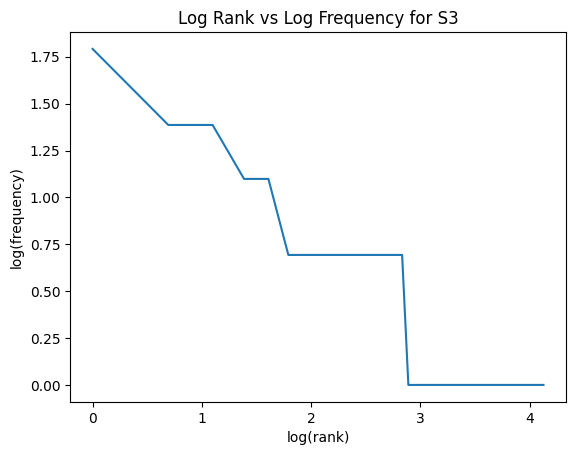

Top 5 bigrams in S1:
[(('.', 'the'), 7), (('yesterday', '.'), 5), (('.', 'i'), 4), (('failed', 'to'), 4), (('to', 'open'), 4)]
Top 5 bigrams in S3:
[(('failed', 'open'), 4), (('worked', 'yesterday'), 3), (('open', 'please'), 2), (('please', 'resolve'), 2), (('since', 'yesterday'), 2)]


In [19]:
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():
    ticket = row['Ticket_Text']
    p = process_ticket(ticket)

    S1.extend(p['tokens'])
    S2.extend([t for t in p['tokens'] if t not in string.punctuation])
    S3.extend(p['final'])

S4 = [porter.stem(t) for t in S3]

def show_statistics(name, tokens):
    print(name)
    print("Total tokens:", len(tokens))
    print("Unique tokens:", len(set(tokens)))
    print("TTR:", len(set(tokens)) / len(tokens) if tokens else 0)
    print()

show_statistics("S1", S1)
show_statistics("S2", S2)
show_statistics("S3", S3)
show_statistics("S4", S4)

print("Top 10 words in S1:", Counter(S1).most_common(10))
print("Top 10 words in S3:", Counter(S3).most_common(10))

frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.plot(np.log(ranks), np.log(frequencies))
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log Rank vs Log Frequency for S3")
plt.show()

print("Top 5 bigrams in S1:")
print(Counter(nltk.ngrams(S1, 2)).most_common(5))

print("Top 5 bigrams in S3:")
print(Counter(nltk.ngrams(S3, 2)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*The TTR decreases from 0.6966 in S3 to 0.6517 in S4 because Porter stemming converts different words into common stems, reducing the number of unique tokens from 62 to 58 while the total number of tokens remains 89. Compared with S1, stopword and punctuation removal increases TTR in S3.